# Erase pretraining, from scratch

A colour word + a reset scene -> the picture with that cube removed. Step 15 (stage 1), kept on during demos in 21a.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from types import SimpleNamespace as namespace

import numpy as np
import torch
from numpy.typing import NDArray
from torch import Tensor

from dream_robot.policies.verne import vae
from dream_robot.policies.verne.data import load_erased, load_scenes
from nbtools import NotebookCache, probe, show

cache, clear_cache = NotebookCache.here().split()

## 0. The whole thing: data


In [3]:
data = namespace(
    scenes=load_scenes('train', vae.WEIGHTS),
    erased=load_erased('train', vae.WEIGHTS),
)
show(
    data.scenes.latent.shape,
    data.erased.shape,
)

data.scenes.latent.shape = torch.Size([1000, 4, 16, 32])
data.erased.shape = torch.Size([1000, 2, 4, 16, 32])


**1000 reset scenes, each with 2 erased versions.**

- `data.scenes.latent`: the first frame of each scene (the [top | wrist] canvas through the frozen VAE): 4 channels x 16 x 32.
- `data.erased[i, k]`: the same scene with the cube in slot k hidden (0 = near, 1 = far), rendered again and encoded.
- No demos, no actions: a reset, two re-renders, done.


## 0b. One scene and its two erased versions, as pictures


In [4]:
vq = vae.load(vae.WEIGHTS)


def decode(z: Tensor) -> NDArray[np.uint8]:
    # normalised latent [Z, 16, 32] -> picture [128, 256, 3] uint8 (top | wrist)
    x = vq.dec((z.float() * vq.z_std[:, None, None] + vq.z_mean[:, None, None])[None])
    return ((x[0].clamp(-1, 1) + 1) * 127.5).byte().permute(1, 2, 0).cpu().numpy()

In [5]:
@probe
def _():
    show(
        data.scenes.colours.shape,
        data.scenes.colours[0],
    )

data.scenes.colours.shape = torch.Size([1000, 2])
data.scenes.colours[0] = tensor([2, 3], device='cuda:0')


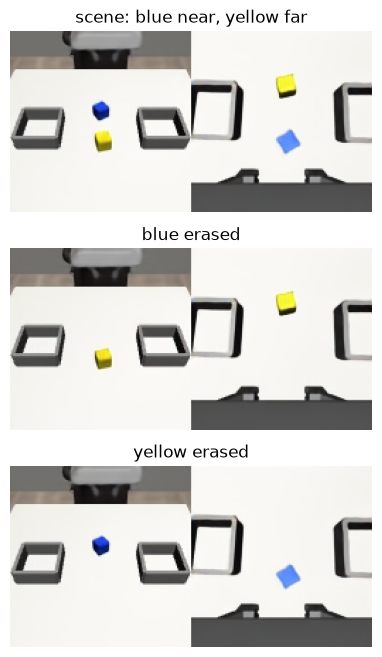

In [6]:
import matplotlib.pyplot as plt

COLOURS = ('red', 'green', 'blue', 'yellow')
i = 0
near, far = (COLOURS[c] for c in data.scenes.colours[i].tolist())
pics = [decode(data.scenes.latent[i]), decode(data.erased[i, 0]), decode(data.erased[i, 1])]
titles = [f'scene: {near} near, {far} far', f'{near} erased', f'{far} erased']
fig, axes = plt.subplots(3, 1, figsize=(6, 8))
for ax, pic, t in zip(axes, pics, titles):
    ax.imshow(pic)
    ax.set_title(t)
    ax.axis('off')

**Scene 0: blue near, yellow far. Each erased version has exactly one cube gone, in both cameras.**

- Left half = top camera, right half = wrist camera (the canvas the policy sees).
- Everything else (boxes, table, gripper) is the same in all three: the only difference is the hidden cube.
- So `data.erased[i, k] - data.scenes.latent[i]` is non-zero only where cube k was: that change is the training target.


## 0c. The target: erased − scene, per latent cell


In [7]:
change = (
    data.erased[i].float() - data.scenes.latent[i].float()
)  # [2, Z, 16, 32]: hide near, hide far
size = change.abs().sum(1)  # [2, 16, 32]: how much each latent cell changes
show(
    change.shape,
    size.amax((1, 2)),
    (size > 0.1 * size.amax()).sum((1, 2)),
)

change.shape = torch.Size([2, 4, 16, 32])
size.amax((1, 2)) = tensor([ 9.1898, 12.4000], device='cuda:0')
(size > 0.1 * size.amax()).sum((1, 2)) = tensor([38, 39], device='cuda:0')


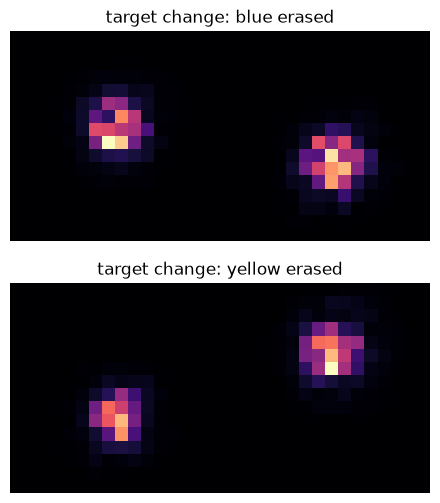

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))
for ax, s, t in zip(axes, size.cpu(), titles[1:]):
    ax.imshow(s, cmap='magma')
    ax.set_title(f'target change: {t}')
    ax.axis('off')

**The target is two small blobs: the named cube in the top view and in the wrist view; the rest is ~0.**

- About 38 of the 512 latent cells (16 x 32) change by more than 10% of the peak, about 7%.
- Blue erased vs yellow erased: same scene, blobs in different places. Only the colour word can say which map is wanted.
- Blobs are wider than the cube: the VAE spreads a cube over its neighbouring cells, and the shadow goes too.


## 0d. Train it (the package's erase pretraining, `pretrain.pretrain`)

Held-out scenes for the val numbers, the T5 demos' joint stats (the arm's state input is normalised by them), then train.


In [9]:
val = namespace(
    scenes=load_scenes('val', vae.WEIGHTS),
    erased=load_erased('val', vae.WEIGHTS),
)
show(val.scenes.latent.shape)

val.scenes.latent.shape = torch.Size([200, 4, 16, 32])


In [10]:
from dream_robot.policies.verne.data import load_table
from dream_robot.policies.verne.run import TASKS, split

state, _, episode = load_table(TASKS['t5'][0])
train_ids, _ = split('t5', int(episode.max()) + 1)
s = torch.tensor(state[np.isin(episode, train_ids)], device='cuda')
stats = namespace(mean=s.mean(0), std=s.std(0))  # [8] each
show(stats.mean)

stats.mean =
tensor([-0.0191,  0.5834,  0.0108, -2.1917, -0.0078,  2.8417,  0.7663,  0.6824],
       device='cuda:0')


In [11]:
from dream_robot.policies.verne import pretrain as pt


@cache
def train(steps: int, seed: int) -> dict[str, Tensor]:
    # erase pretraining from a fresh Verne -> its weights (cpu)
    return pt.pretrain(
        data.scenes, data.erased, val.scenes, val.erased, stats.mean, stats.std, steps, seed=seed
    )['weights']

train: cached, 1 call(s) stored


In [12]:
weights = train(2000, 0)

step      0   train 0.3989   val right 0.4301   wrong 0.4300   erase acc 0.480
step   1000   train 0.0071   val right 0.0089   wrong 0.3619   erase acc 1.000
step   2000   train 0.0051   val right 0.0070   wrong 0.3660   erase acc 1.000


**Erase accuracy 48% -> 100% by step 1000; the right word's loss falls 50x, the wrong word's stays.**

- val right 0.430 -> 0.0070: given the right colour word, it draws the right change.
- val wrong 0.366: the same prediction scored against the _other_ cube's change. Big gap = the word decides which cube.
- At step 0 right = wrong (0.430): an untrained net ignores the word.
- erase acc: the predicted change is larger on the named cube's cells than on the other cube's (chance 50%).


## 0e. Its predictions next to the targets (held-out scene)


In [13]:
from dream_robot.policies.verne.data import colour_prompts
from dream_robot.policies.verne.model import Verne

net = Verne().cuda().eval()
net.load_state_dict(weights)

<All keys matched successfully>

In [14]:
j = torch.tensor([0, 0], device='cuda')  # val scene 0, twice
which = torch.tensor([0, 1], device='cuda')  # the near cube's colour word, then the far cube's
with torch.no_grad():
    pred = net.edit(
        val.scenes.latent[j].float(),
        pt.scene_state(val.scenes, j, stats.mean, stats.std),
        colour_prompts(val.scenes, j, which),
    )
target = pt.target(val.scenes, val.erased, j, which)
show(
    pred.shape,
    (pred - target).pow(2).mean((1, 2, 3)),
)

pred.shape = torch.Size([2, 4, 16, 32])
(pred - target).pow(2).mean((1, 2, 3)) = tensor([0.0040, 0.0065], device='cuda:0')


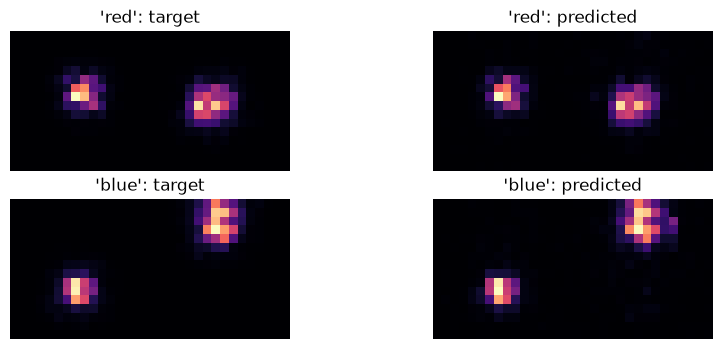

In [15]:
near, far = (COLOURS[c] for c in val.scenes.colours[0].tolist())
fig, axes = plt.subplots(2, 2, figsize=(10, 4))
for r, word in enumerate((near, far)):
    for c, (z, kind) in enumerate(((target[r], 'target'), (pred[r], 'predicted'))):
        axes[r, c].imshow(z.abs().sum(0).cpu(), cmap='magma')
        axes[r, c].set_title(f"'{word}': {kind}")
        axes[r, c].axis('off')

**Held-out scene (red near, blue far): each word's predicted change sits on its own cube, in both cameras.**

- 'red' -> blobs on the red cube; 'blue' -> on the blue cube. Same picture in, only the word differs.
- Per-word error 0.0040 / 0.0065 (val right overall 0.0070): the shapes match, slightly blurrier.
- This is the whole of erase pretraining. The next steps open the boxes: the model's edit path, the loss, and why the answer is read where the arm reads.


## 1. Inside `net.edit`: the frame becomes 128 patch tokens

`edit` = `video_side` (patches -> 4 transformer layers, words + joints by cross-attention) -> `edit_out` on the tokens entering the last layer -> back to a latent. First piece: patches.


In [16]:
from einops import rearrange

from dream_robot.policies.verne.model import P

frame = val.scenes.latent[:1].float()  # [1, Z, 16, 32], val scene 0
patches = rearrange(frame, 'b c (h p) (w q) -> b (h w) (p q c)', p=P, q=P)
tokens = net.patch_in(patches)
show(
    P,
    patches.shape,
    tokens.shape,
)

P = 2
patches.shape = torch.Size([1, 128, 16])
tokens.shape = torch.Size([1, 128, 256])


**128 tokens of width 256: one per 2 x 2 block of latent cells.**

- Latent 16 x 32 -> 8 x 16 blocks = 128 patches; each holds 2 x 2 cells x 4 channels = 16 numbers.
- In pixels a patch is 16 x 16 of the 128 x 256 canvas: patches go row by row (8 rows of 16); in each row the first 8 are the top camera, the last 8 the wrist (64 each).
- `patch_in` (one linear layer, 16 -> 256) turns each into a token. The words and joints are not tokens here: they come in later, by cross-attention.


## 2. The rows the tokens cross-attend to: words + joints

`rows_of`: every word's embedding as a row (row 0 = 'no word'), then the joints as one row; a mask says which rows this prompt may read.


In [17]:
from dream_robot.policies.verne.data import WORDS
from dream_robot.policies.verne.model import rows_of

ins = colour_prompts(val.scenes, j[:1], which[:1])  # val scene 0, the near cube's colour word
state = pt.scene_state(val.scenes, j[:1], stats.mean, stats.std)  # [1, 16]: joints (previous, now)
rows, rmask = rows_of(net.video_words, net.video_state, ins, state)
show(
    ('no word', *WORDS, 'joints'),
    ins,
    rows.shape,
    rmask,
)

('no word', *WORDS, 'joints') = ('no word', 'near', 'far', 'red', 'green', 'blue', 'yellow', 'left', 'right', 'joints')
ins = tensor([[0., 0., 1., 0., 0., 0., 0., 0.]], device='cuda:0')
rows.shape = torch.Size([1, 10, 256])
rmask =
tensor([[ True, False, False,  True, False, False, False, False, False,  True]],
       device='cuda:0')


**10 rows of width 256; this prompt may read 3 of them: 'no word', 'red', the joints.**

- The erase prompt is one colour word only ('red'), no side word: `ins` is one-hot at 'red'.
- All 9 word rows are always there (the embedding table); the mask hides the 6 words not in the prompt.
- 'no word' is always readable, so a token that needs nothing from the prompt has somewhere to attend.
- Joints: one row from a small MLP on (previous, now) joints; for a reset scene previous = now.


## 3. The 4 video layers by hand, then `edit_out`

Each layer: self-attention over the 128 patch tokens, cross-attention to the rows, an MLP. The edit is read from the tokens _entering_ the last layer (layer 3's keys and values are what the arm's last layer reads), so only layers 0-2 run to the end.


In [18]:
from dream_robot.policies.verne.model import LAYERS, N_PATCH

x = tokens
for i, block in enumerate(net.video[: LAYERS - 1]):  # layers 0, 1, 2
    q, k, v = block.qkv_of(x, net.video_angles[:N_PATCH])
    x = block.finish(x, q, k, v, rows, rmask)
show(x.shape)

x.shape = torch.Size([1, 128, 256])


In [19]:
out = net.edit_out(x)  # [1, 128, 16]: each token -> its own patch's change
mine = rearrange(out, 'b (h w) (p q c) -> b c (h p) (w q)', h=16 // P, p=P, q=P)
show(
    mine.shape,
    (mine - pred[:1]).abs().max(),
)

mine.shape = torch.Size([1, 4, 16, 32])
(mine - pred[:1]).abs().max() = tensor(1.6689e-06, device='cuda:0', grad_fn=<MaxBackward1>)


**By hand = `net.edit` (max difference 1.7e-6, float rounding).**

- `edit_out` is one linear layer, 256 -> 16: each token writes only its own patch's change. No token can paint another patch.
- So to erase the red cube, the tokens _on_ the red cube must know, by the end of layer 2, "the prompt names me". That knowledge, sitting on the named cube's own patches, is the mark.
- Layer 3's keys and values (from these same tokens) are what the arm's last layer reads: the mark is where the arm looks.


## 4. Which patches read the colour word

Inside `finish`: self-attention, then each token's cross-attention weights over the 10 rows. Take the weight on the prompt's colour row, averaged over the 4 heads, per patch.


In [20]:
import torch.nn.functional as F

from dream_robot.policies.verne.model import HEAD_DIM, HEADS, Block


def word_weight(
    block: Block, x: Tensor, q: Tensor, k: Tensor, v: Tensor, rows: Tensor, rmask: Tensor, row: int
) -> Tensor:
    # [128]: each patch's cross-attention weight on rows[:, row], mean over heads
    a = F.scaled_dot_product_attention(q, k, v)
    h = x + block.out(rearrange(a, 'b h s d -> b s (h d)'))  # after self-attention
    cq = rearrange(block.cq(block.norm3(h)), 'b s (h d) -> b h s d', h=HEADS)
    ck = rearrange(block.ckv(rows), 'b s (n h d) -> n b h s d', n=2, h=HEADS)[0]
    w = (cq @ ck.transpose(-1, -2) / HEAD_DIM**0.5).masked_fill(~rmask[:, None, None], -torch.inf)
    return w.softmax(-1)[0, :, :, row].mean(0)

In [21]:
def word_maps(colour: str) -> list[Tensor]:
    # val scene 0 with the prompt `colour` -> per layer 0-2, each patch's weight on that word's row [8, 16]
    ins = torch.tensor([[float(w == colour) for w in WORDS]], device='cuda')
    rows, rmask = rows_of(net.video_words, net.video_state, ins, state)
    row = 1 + WORDS.index(colour)  # row 0 = 'no word'
    x = tokens
    maps: list[Tensor] = []
    with torch.no_grad():
        for block in net.video[: LAYERS - 1]:
            q, k, v = block.qkv_of(x, net.video_angles[:N_PATCH])
            maps.append(word_weight(block, x, q, k, v, rows, rmask, row).view(8, 16).cpu())
            x = block.finish(x, q, k, v, rows, rmask)
    return maps

In [22]:
maps = word_maps(near)
show(
    near,
    [round(m.mean().item(), 3) for m in maps],
    [round(m.max().item(), 3) for m in maps],
)

near = 'red'
[round(m.mean().item(), 3) for m in maps] = [0.431, 0.059, 0.049]
[round(m.max().item(), 3) for m in maps] = [0.67, 0.664, 0.407]


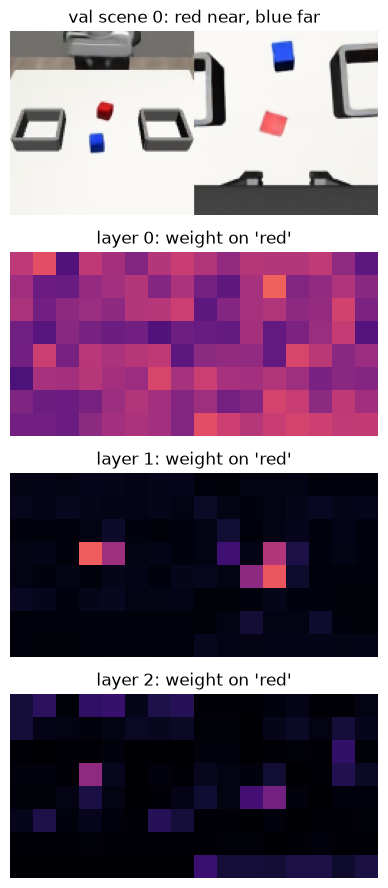

In [23]:
fig, axes = plt.subplots(4, 1, figsize=(6, 11))
axes[0].imshow(decode(val.scenes.latent[0]))
axes[0].set_title(f'val scene 0: {near} near, {far} far')
for ax, m, layer in zip(axes[1:], maps, range(3)):
    ax.imshow(m, cmap='magma', vmin=0, vmax=1)
    ax.set_title(f"layer {layer}: weight on '{near}'")
for ax in axes:
    ax.axis('off')

**Layer 1 reads 'red' on the red cube's patches, in both cameras, and almost nowhere else.**

- Layer 0: everyone reads 'red' a bit (mean 0.43 of the 3 readable rows): no colour is known yet, the word is broadcast.
- Layer 1: mean 0.06, but up to 0.66 on the red cube's patches (top view and wrist view); the blue cube's patches don't read it.
- Layer 2: weaker (max 0.41), still mostly on the red cube.
- So the lookup happens on the cube itself: a patch that sees red pixels pulls in the 'red' row. That's the colour -> place binding, on the patches `edit_out` and the arm read.


## 5. Same scene, the other word: does the hot spot move?

If the lookup is colour -> place, 'blue' should light up the blue cube's patches instead.


In [24]:
other = word_maps(far)
show(
    far,
    [round(m.mean().item(), 3) for m in other],
    [round(m.max().item(), 3) for m in other],
)

far = 'blue'
[round(m.mean().item(), 3) for m in other] = [0.304, 0.318, 0.118]
[round(m.max().item(), 3) for m in other] = [0.738, 0.612, 0.408]


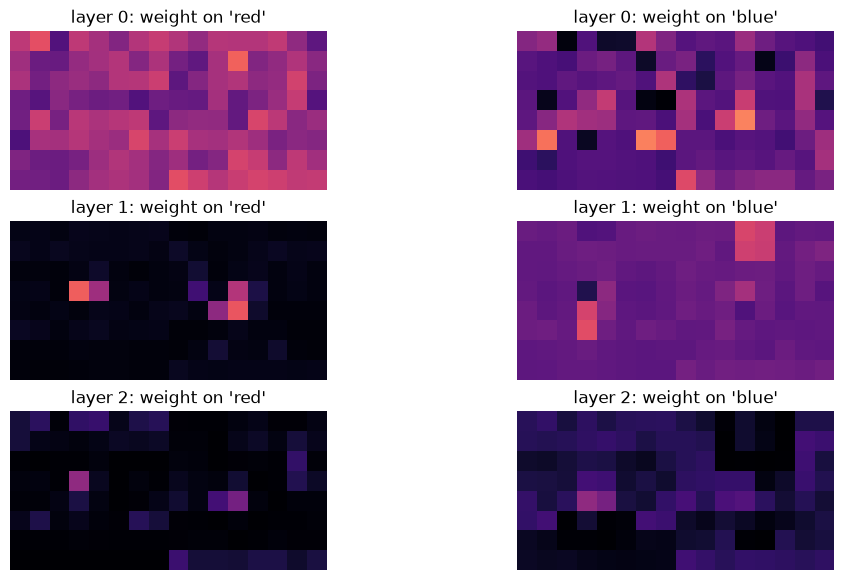

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(12, 7))
for layer in range(3):
    for c, (word, m) in enumerate(((near, maps[layer]), (far, other[layer]))):
        axes[layer, c].imshow(m, cmap='magma', vmin=0, vmax=1)
        axes[layer, c].set_title(f"layer {layer}: weight on '{word}'")
        axes[layer, c].axis('off')

**The hot spot moves: with 'blue', layer 1's peaks are on the blue cube (top view and wrist view), not the red one.**

- Same picture, same tokens in; only the word changed, and the patches that read it changed with it: colour -> place.
- Not symmetric: 'blue' is also read faintly everywhere in layer 1 (mean 0.32 vs 'red' 0.06). A weight is a share of 3 rows ('no word', the colour, joints), and what a row adds depends on its value too, so a flat background share needn't change the tokens much.
- One scene, one trained net: a picture of the mechanism, not a measurement. The locate probe (later) is the measurement.


## 6. The measurement: locate probe (the package's `pretrain.locate_probe`)

Every scene twice (each cube's colour word). A linear head, shared by all patches, reads the token entering the last layer and scores 'named cube here'; trained on the 1000 train scenes, scored on the 200 val. `named_gt_other`: share of val (scene, word) where the named cube's patches score higher than the other cube's. Chance 50%.


In [26]:
torch.manual_seed(0)
untrained = Verne().cuda()  # the floor for both probes

In [27]:
locate = {
    name: pt.locate_probe(
        m, data.scenes, val.scenes, data.erased, val.erased, stats.mean, stats.std
    )
    for name, m in (('untrained', untrained), ('erase 2k steps', net))
}
show(locate)

locate probe: named > other 0.517   auc 0.883
locate probe: named > other 1.000   auc 0.986
locate = {'untrained': {'named_gt_other': 0.5174999833106995, 'auc': 0.8832252621650696}, 'erase 2k steps': {'named_gt_other': 1.0, 'auc': 0.9859693646430969}}


**Named > other: untrained 51.7% (chance), erase 2k steps 100%.**

- On every one of the 400 val (scene, word) pairs, the named cube's own patches carry the mark more than the other cube's.
- AUC (named cube's patches vs all others) is high even untrained (0.88): _finding cubes_ is easy, any token knows 'I am a cube'. _Which_ cube is named is the hard part, and only training on erase gives it.
- Earlier steps, same probe: clip pretraining 55% (19), 72% best (19j); erase then demos 76-83% (step 20); erase kept on during demos 100% (21a).


## 7. The other probe: whole frame (the package's `pretrain.binding_probe`)

Same tokens (entering the last layer), but all 128 flattened into one vector (32,768 numbers) and one linear classifier: is the named cube near or far? The answer may sit anywhere in the frame, not necessarily on the cube. Prompt = the reset's own ('red left').


In [28]:
whole = {
    name: pt.binding_probe(m, data.scenes, val.scenes, stats.mean, stats.std)['colour']
    for name, m in (('untrained', untrained), ('erase 2k steps', net))
}
show(whole)

probe, prompt colour: train 1.000   val 0.710
probe, prompt both  : train 1.000   val 1.000
probe, prompt colour: train 1.000   val 0.990
probe, prompt both  : train 1.000   val 1.000
whole = {'untrained': {'train': 1.0, 'val': 0.7099999785423279}, 'erase 2k steps': {'train': 1.0, 'val': 0.9899999499320984}}


**Whole frame: untrained already 71% (val), erase 99%. The floor is far above chance.**

- Untrained 71%: random layers keep enough of the colours and places that a classifier on 32,768 numbers can partly work out 'red is near' by itself. Train is 100% for both (1000 scenes, 32,768 features: it can memorise).
- Both probes, same nets, and what the earlier steps scored:

```-
                              whole frame (val)   named cube's own patches
untrained                     71%                 52%
erase, this notebook          99%                 100%
clip pretraining (19 / 19j)   81.5% / 92%         55% / 72%
erase then demos (step 20)    94.5%               76-83%
```

- Whole frame says clips are nearly as good as erase; per patch says they aren't. The arms agreed with per patch (clip inits 21-29 of 50, erase 41-48): the arm reads patches, so the answer has to be _on the cube_.
